[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/13-fine-tuning/notebooks/02-quantisation-explained.ipynb)

# 02 - Quantisation explained (the "Q" in QLoRA)

**Goal:** see how 4-bit quantisation works on real numbers, measure the error it adds, understand why NF4 places its levels the way it does, and estimate GPU memory for different fine-tuning methods.

**Words you need**
- **Quantisation** - storing numbers with fewer bits by rounding them to a small set of allowed values.
- **Bit** - a 0 or 1. With 4 bits you can label 2^4 = 16 different values.
- **Scale** - the number we divide by before rounding and multiply by afterwards.
- **Block-wise** - quantising small groups of numbers separately, each with its own scale.

The real 4-bit library (`bitsandbytes`) needs an NVIDIA GPU, so here we write the maths ourselves on a CPU.

## Step 1 - Imports and some fake weights

Neural-network weights are roughly bell-shaped (a **normal distribution**): many values near zero, few large. We also plant a few **outliers** (unusually large values), because real models have them.

min -0.08187474310398102 max 0.4000000059604645


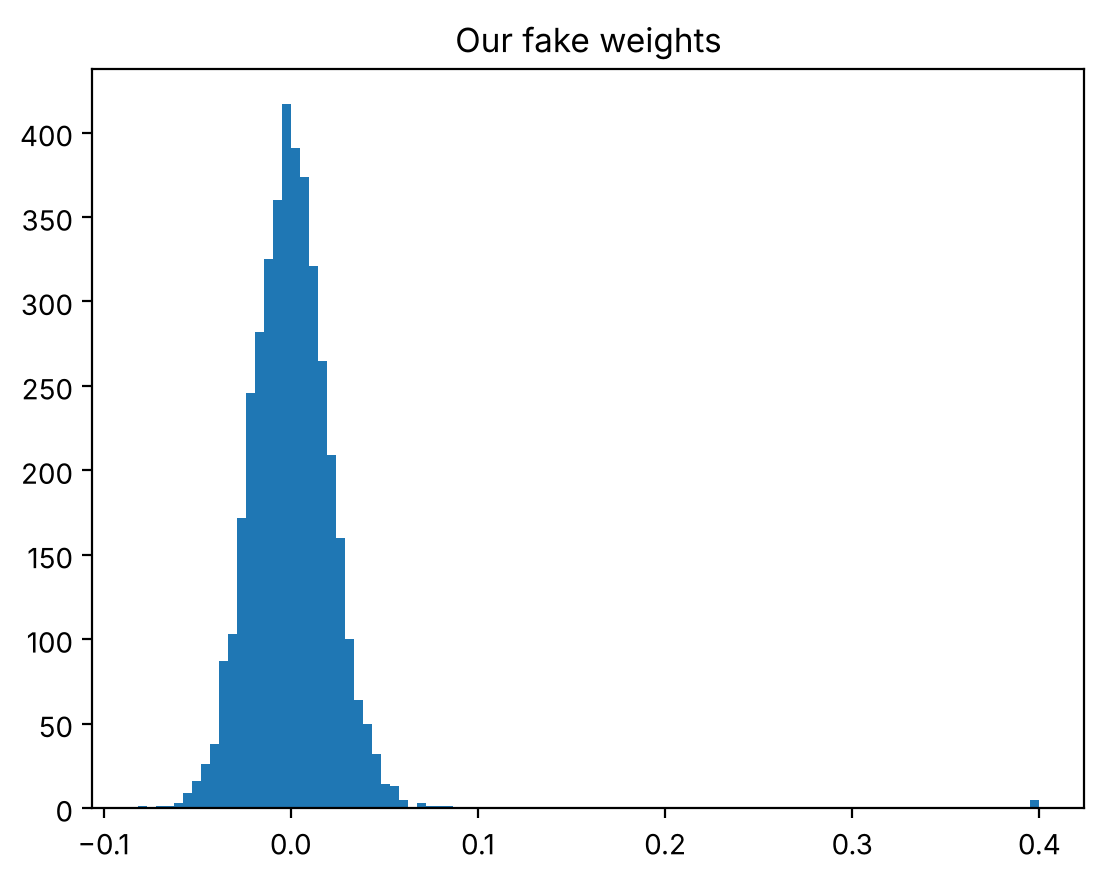

In [1]:
import torch
import matplotlib.pyplot as plt
torch.manual_seed(0)
w = torch.randn(4096) * 0.02             # typical small weights
w[torch.randint(0, 4096, (5,))] = 0.4    # a few outliers
print("min", w.min().item(), "max", w.max().item())
plt.hist(w, bins=100); plt.title("Our fake weights"); plt.show()

## Step 2 - Bytes per weight

The same model takes very different amounts of memory depending on the format.

In [2]:
formats = {"float32": 4, "bfloat16 / float16": 2, "int8": 1, "4-bit": 0.5}
for params_b in [0.5, 7, 70]:
    row = ", ".join(f"{name}: {params_b * b:.1f} GB" for name, b in formats.items())
    print(f"{params_b:>4}B params -> {row}")

 0.5B params -> float32: 2.0 GB, bfloat16 / float16: 1.0 GB, int8: 0.5 GB, 4-bit: 0.2 GB
   7B params -> float32: 28.0 GB, bfloat16 / float16: 14.0 GB, int8: 7.0 GB, 4-bit: 3.5 GB
  70B params -> float32: 280.0 GB, bfloat16 / float16: 140.0 GB, int8: 70.0 GB, 4-bit: 35.0 GB


## Step 3 - Absmax quantisation of the whole tensor

Recipe for symmetric 4-bit (integers -7..7):
1. scale = max(|w|) / 7
2. q = round(w / scale), clipped to -7..7 - these small integers are what we store
3. dequantise: w_hat = q x scale

Because of the outliers, the scale is large, so most small weights round to 0. Look at the error.

In [3]:
def absmax_quant(x, bits=4):
    qmax = 2 ** (bits - 1) - 1                    # 7 for 4-bit, 127 for 8-bit
    scale = x.abs().max() / qmax
    q = torch.clamp(torch.round(x / scale), -qmax, qmax)
    return q, scale

def dequant(q, scale):
    return q * scale

for bits in [8, 4]:
    q, s = absmax_quant(w, bits)
    err = (w - dequant(q, s)).abs().mean().item()
    zeros = (q == 0).float().mean().item()
    print(f"{bits}-bit whole tensor: mean abs error {err:.5f}, {zeros:.0%} of weights became 0")

8-bit whole tensor: mean abs error 0.00079, 7% of weights became 0
4-bit whole tensor: mean abs error 0.01308, 86% of weights became 0


## Step 4 - Block-wise quantisation

Split the tensor into blocks of 64 and give each block its own scale. An outlier now only hurts its own block. Storing one extra scale per 64 weights costs a little memory, which is why real 4-bit formats use slightly more than 0.5 bytes per weight (and why QLoRA's **double quantisation** compresses the scales too).

In [4]:
def blockwise(x, bits=4, block=64):
    blocks = x.view(-1, block)
    out = torch.empty_like(blocks)
    for i, b in enumerate(blocks):
        q, s = absmax_quant(b, bits)
        out[i] = dequant(q, s)
    return out.view(-1)

w4_block = blockwise(w, 4, 64)
print("4-bit block-wise mean abs error:", round((w - w4_block).abs().mean().item(), 5))

4-bit block-wise mean abs error: 0.0027


## Step 5 - NF4-style levels: put more levels where the weights are

Uniform levels waste values on the rare large numbers. **NF4 (4-bit NormalFloat)** chooses its 16 levels from the **quantiles** of a normal distribution - points that split the bell curve into equal-probability slices - so levels are dense near zero. The real NF4 table is built this way with an extra trick so that 0 is exactly representable; here we build a simple version.

In [5]:
normal = torch.distributions.Normal(0, 1)
probs = torch.linspace(0.02, 0.98, 16)
nf_levels = normal.icdf(probs)
nf_levels = nf_levels / nf_levels.abs().max()          # scale to -1..1
uniform_levels = torch.linspace(-1, 1, 16)
print("NF4-style levels:", [round(v, 2) for v in nf_levels.tolist()])

def quant_to_levels(x, levels, block=64):
    blocks = x.view(-1, block)
    out = torch.empty_like(blocks)
    for i, b in enumerate(blocks):
        s = b.abs().max()
        idx = torch.argmin((b[:, None] / s - levels[None, :]).abs(), dim=1)  # nearest level
        out[i] = levels[idx] * s
    return out.view(-1)

for name, lv in [("uniform 16 levels", uniform_levels), ("NF4-style levels", nf_levels)]:
    err = (w - quant_to_levels(w, lv)).abs().mean().item()
    print(f"{name:18s}: mean abs error {err:.5f}")

NF4-style levels: [-1.0, -0.67, -0.51, -0.39, -0.29, -0.2, -0.12, -0.04, 0.04, 0.12, 0.2, 0.29, 0.39, 0.51, 0.67, 1.0]
uniform 16 levels : mean abs error 0.00277
NF4-style levels  : mean abs error 0.00200


## Step 6 - See the levels against the weights

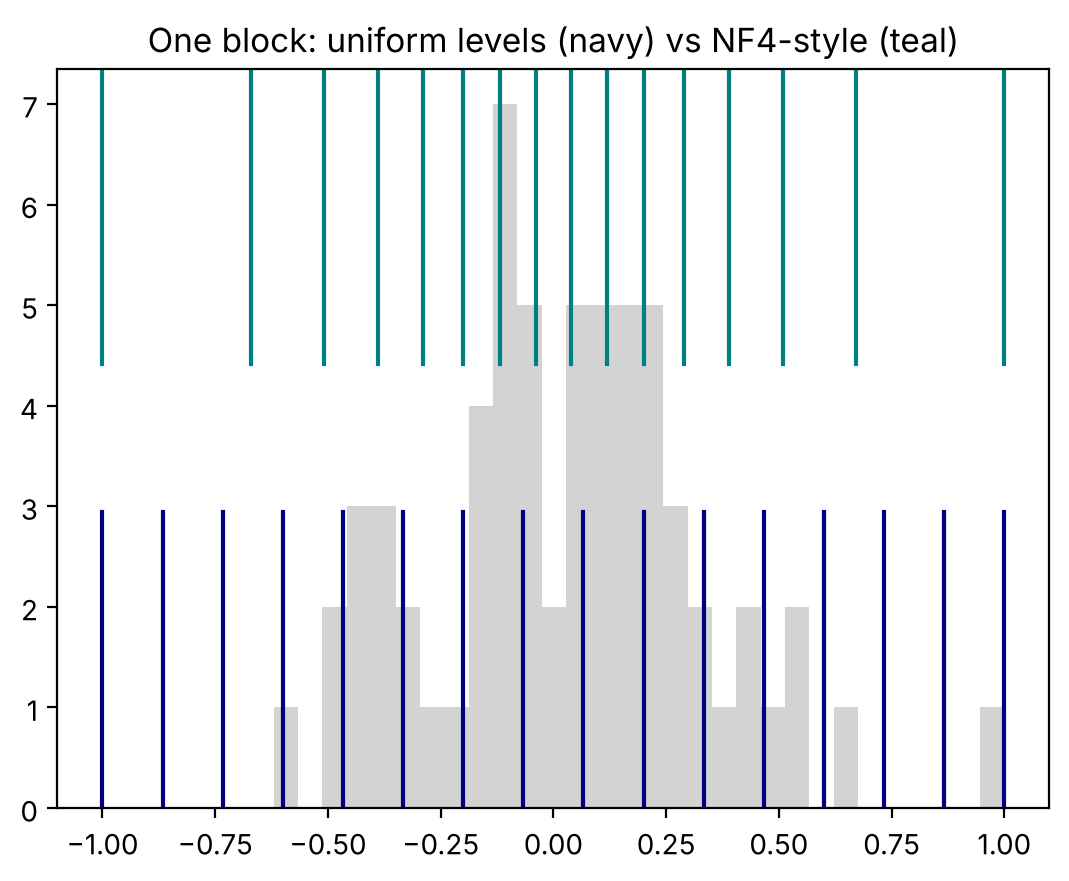

In [6]:
b = w.view(-1, 64)[0]
b = b / b.abs().max()
plt.hist(b, bins=30, color="lightgrey")
for v in uniform_levels: plt.axvline(v, color="navy", ymax=0.4)
for v in nf_levels: plt.axvline(v, color="teal", ymin=0.6)
plt.title("One block: uniform levels (navy) vs NF4-style (teal)"); plt.show()

## Step 7 - A GPU memory estimator

Rough rule-of-thumb formulas (the same ones used in `excel/gpu-memory-estimator.xlsx`):
- **weights** = parameters x bytes per weight (2 for 16-bit, ~0.55 for 4-bit including scales)
- **training state** = trainable parameters x bytes for gradient + optimizer (about 14 extra for full fine-tuning with Adam in mixed precision; about 16 for LoRA adapters kept in 32-bit)
- **activations** = depends on batch size and sequence length; we use a rough fixed guess

These are planning numbers, not guarantees.

In [7]:
def estimate_gb(params_b, method, activations_gb=2.0, lora_fraction=0.005):
    p = params_b * 1e9
    if method == "inference-16bit":
        weights, state, act = 2 * p, 0, 0.5
    elif method == "full":
        weights, state, act = 2 * p, 14 * p, activations_gb
    elif method == "lora":
        weights, state, act = 2 * p, 16 * p * lora_fraction, activations_gb
    elif method == "qlora":
        weights, state, act = 0.55 * p, 16 * p * lora_fraction, activations_gb
    return (weights + state) / 1e9 + act

print(f"{'model':>6} | {'inference':>9} | {'full FT':>8} | {'LoRA':>6} | {'QLoRA':>6}   (GB, rough)")
for size in [0.5, 1.5, 7, 13]:
    vals = [estimate_gb(size, m) for m in ["inference-16bit", "full", "lora", "qlora"]]
    print(f"{size:>5}B | " + " | ".join(f"{v:>8.1f}" for v in vals))
print("A free Colab T4 has 16 GB (about 15 usable).")

 model | inference |  full FT |   LoRA |  QLoRA   (GB, rough)
  0.5B |      1.5 |     10.0 |      3.0 |      2.3
  1.5B |      3.5 |     26.0 |      5.1 |      2.9
    7B |     14.5 |    114.0 |     16.6 |      6.4
   13B |     26.5 |    210.0 |     29.0 |     10.2
A free Colab T4 has 16 GB (about 15 usable).


## Step 8 - How you load a model in 4-bit (GPU only, not run here)

On a GPU with `bitsandbytes` installed, this is all it takes. Notebook `04-qlora-colab-only.ipynb` runs it for real.

```python
import torch
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct",
                                             quantization_config=bnb, device_map="auto")
```

## What you learned

- 4-bit storage = one quarter of 16-bit memory, at the cost of rounding error.
- Block-wise scales stop outliers from ruining everything.
- NF4 puts more levels near zero because weights are bell-shaped.
- QLoRA = 4-bit frozen base + 16-bit LoRA adapters; full fine-tuning needs roughly 16 bytes per parameter.